## Tarefa 1

O que é esperado encontrar nesse notebook
1. Uso do dataset MNIST
2. Implementação de uma NN
3. Implementação de uma CNN
4. Comparar resultados da NN com a CNN com um número comparável de parâmetros
5. Testar em outros datasets como por exemplo CIFAR 10
6. Modificar imagens - manter tamanho 28x28 mas reduzir reduzir escala e/ou deslocar e/ou adicionar ruido e/ou borrar imagem
7. Utilizar uma quantidade muito menor de dados por classe (50, 100, 500), ou ainda, utilizar classes bem desbalanceadas no conjunto de treinamento
8. Teste de hiperparâmetros - alterar número de camdas/filtros, tipos de ativação, inicialização de pesos, learning rate, otimizador, batch size, entre outros

In [2]:
# importando pacotes
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, random_split
import torchvision.datasets.mnist as tMNIST
from torchvision import transforms
import matplotlib.pyplot as plt
import torchvision.transforms.functional as torchFunc
import torch.optim as optim


## Loading Dataset
This section we'll load the dataset and show an image as example

In [27]:
# Downloading MNIST
dataset = tMNIST.MNIST(
    "./data",
    train=True,
    download=True,
    transform=transforms.ToTensor(),
)

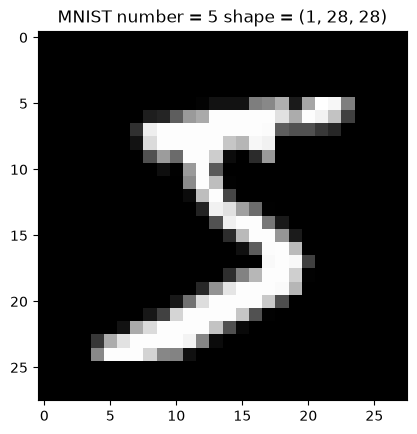

In [109]:
# Showing MNIST dataset
image, target = dataset[0]
input_size_flatten = image.numel()
classes_size = len(dataset.classes)
plt.title(f"MNIST number = {target} shape = {tuple(image.shape)}")
plt.imshow(image.squeeze().numpy(), cmap='gray')

In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


## Dataset Preparation
Nessa seção iremos realizar a preparação do dataset em treinamento e validação

In [ ]:
train_share = 0.7
val_share = 0.15
test_share = 0.15

train_dataset, val_dataset, test_dataset = random_split(dataset, 
                                                        [train_share, val_share, test_share],
                                                        generator=torch.Generator().manual_seed(31))

batch_size = 128 if device.type == "cuda" else 32
pin_memory = device.type == "cuda"

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, pin_memory=pin_memory)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, pin_memory=pin_memory)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, pin_memory=pin_memory)

print(f"Train size: {len(train_dataset)}, Validation size: {len(val_dataset)}, Test size: {len(test_dataset)}")
print(f"Batch size: {batch_size}, Pin memory: {pin_memory}")

Train size: 7000, Validation size: 1500, Test size: 1500


## Definindo rede neural
Nesta seção estamos criando uma rede neural

In [ ]:
class NeuralNetwork(nn.Module):
	def __init__(self, inputSize, classes_size) -> None:
		super(NeuralNetwork, self).__init__()
		self.network = nn.Sequential(
			nn.Linear(inputSize, 32),
			nn.ReLU(), # Activation
			nn.Linear(32, 16),
			nn.ReLU(), # Activation
			nn.Linear(16, 8),
			nn.ReLU(), # Activation
			nn.Linear(8, 4),
			nn.ReLU(), # Activation
			nn.Linear(4, 2),
			nn.ReLU(), # Activation
			nn.Linear(2, classes_size),
			nn.Softmax()
		)
		# TODO: add dropout

	def forward(self, x):
		x = torch.flatten(x, start_dim=1)
		return self.network(x)

In [ ]:
x, y = train_loader.dataset[1]

model = NeuralNetwork(input_size_flatten, classes_size).to(device)
print(model(x.to(device)))

tensor([[0.0451, 0.1698, 0.0701, 0.0602, 0.1208, 0.0733, 0.1453, 0.0975, 0.0607,
         0.1571]], grad_fn=<SoftmaxBackward0>)


In [94]:
# Defining loss function
learning_rate = 0.001
criteria = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

In [ ]:
def GradientDescent(train_loader, model, criteria, optimizer, epochs = 100) -> list:
	history = []
	for epoch in range(epochs):
		model.train()
		running_loss = 0.0
		for X, Y in train_loader:
			X = X.to(device, non_blocking=True)
			Y = Y.to(device, non_blocking=True)

			# Forwards pass
			prediction = model(X)
			loss = criteria(prediction, Y)

			# Backward pass
			optimizer.zero_grad()
			loss.backward()
			optimizer.step()
		history.append(loss.item())
	return history

In [114]:
history = GradientDescent(train_loader, model, criteria, optimizer)
print(history)

KeyboardInterrupt: 